<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2013/MRayhanZamzami_JS13_P3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 3 - Regresi Prediksi Harga dengan Keras

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_s = scaler_X.fit_transform(X)
y_s = scaler_y.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

pred = model.predict(X_test)
print("Prediksi (dummy scaled):", pred)

C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step


Prediksi (dummy scaled): [[-0.03312216]]


In [2]:
# Tugas 4: Perbandingan Learning Rate
for lr in [0.001, 0.01, 0.1]:
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = m.fit(X_train, y_train, epochs=100, verbose=0)
    print(f"LR: {lr:<6} Final Loss: {h.history['loss'][-1]:.6f}")

LR: 0.001  Final Loss: 0.389944


LR: 0.01   Final Loss: 0.001907


LR: 0.1    Final Loss: 0.000002


C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


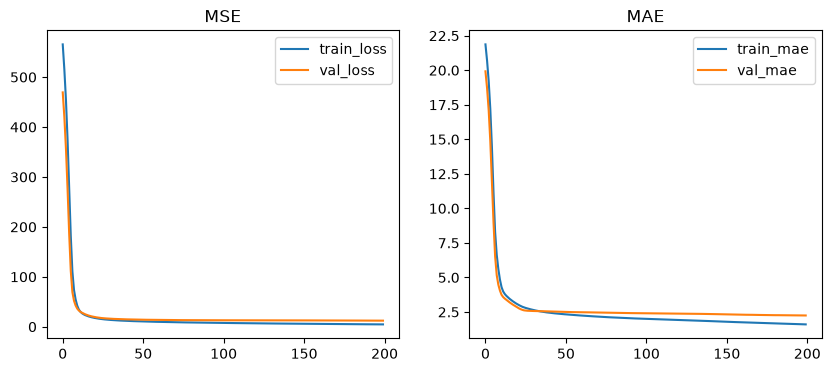

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


RMSE: 3.4867461970030007


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

boston_path = 'dataset/BostonHousing.csv' if os.path.exists('dataset/BostonHousing.csv') else '../dataset/BostonHousing.csv'
df_boston = pd.read_csv(boston_path)

X = df_boston.drop('medv', axis=1).values
y = df_boston['medv'].values

scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])

h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend(); plt.title('MSE')
plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))